# Notebook 05 — PaDiM

This notebook combines a live normal-only mathematical demonstration with explicit
artifact analysis of independently executed, registered pilot, development and
confirmation jobs. Loading a completed result does not rerun or claim to rerun
its benchmark. The original data are licensed MVTec AD; image panels stay local.


## 1. Research question and execution scope

Can spatial normal-feature distributions provide useful detection and localization
without learned anomaly heads or nearest-neighbor memory? We assess ranking,
normal false alarms, defect recall, native localization, latency and storage.
The four earlier models and all their published results remain preserved.

In [1]:
from pathlib import Path
import os,sys,json,inspect,time
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch
from IPython.display import display,Markdown
from anomaly_detection.data import CATEGORIES,sha256,autodiscover_data_root
from anomaly_detection.cnn_research import read_partition,load_resized,require_fitting
from anomaly_detection.padim import PaDiMExtractor,SpatialGaussian,aligned_embedding,anomaly_maps
from anomaly_detection.padim_research import extract,score
from anomaly_detection.basic_cnn import seed_everything
torch.set_num_threads(4)
seed_everything(2026)
torch.backends.cuda.matmul.allow_tf32=False
report=ROOT/'reports/padim'
summary=json.loads((report/'summary.json').read_text())
frozen=json.loads((ROOT/'configs/padim_frozen.json').read_text())
print('Completed category-specific models:',summary['models'])
print('Seeds:',summary['seeds'])

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


Completed category-specific models: 45
Seeds: [2026, 2027, 2028]


Final models use only the frozen fit-normal partition. The benchmark is a
comparison under this repository's protocol; it does not reproduce the paper's
different crop, interpolation, data partition or ten-model ensemble exactly.

## 2. Clean restart and retained foundation

The unsuccessful Milestone 7 attempt was removed before rebuilding. Inspection
identified only untracked PaDiM files and scratch artifacts; no shared tracked
modifications needed reverting. The audit records each precise cleanup action.

In [2]:
display(Markdown((report/'restart_audit.md').read_text()))

# Restart audit

Starting HEAD: `5e3b520538e862dd275bded9abad9a0a8163b814`.
Initial `git status --short` contained only untracked `src/anomaly_detection/padim.py`,
`tests/test_padim.py`, `docs/milestone_status.md`, and `.pytest-tmp/`.
Inspection confirmed the checklist belonged solely to the failed Milestone 7.
The scratch directory contained only the old PaDiM serialization fixture and its
pytest current link. These four explicit workspace paths were removed after
checking resolved paths. Git status was empty immediately afterward.
No tracked/shared changes required reverting. Notebooks 00â€“04 existed; Notebook
05 did not. No PaDiM experiment directory or pilot scripts existed. Recursive
artifact-name inspection found earlier-model pilots, which were preserved.
No dataset/environment/model/report from completed milestones was removed.

The exact `.venv/Scripts/python.exe` imported the existing package successfully;
no editable install, environment creation or dependency reinstall was necessary.
CUDA PyTorch 2.11.0+cu128 and RTX 4060 Laptop GPU were detected; all 15 dataset
category roots were accessible. Environment details are in environment.json.

## Recoverable launch issues

- Initial default pytest run: 62 passed, 36 fixture setup errors caused by sandbox
  access denial to the Windows pytest temporary directory. An approved rerun
  passed 102 tests including the newly added four numerical tests; two cache
  write warnings. Subsequent checks use explicit fresh workspace scratch paths.
- Initial numerical test scratch parent did not exist: three passed, one fixture
  setup error. Created the output parent; all four passed.
- Initial environment-report writer required its parent directory. Created
  `reports/padim`, reran environment capture and pilot successfully. This failed
  before experiment reservation, GPU fitting or data scoring.
- First development launch used a decimal point in its experiment ID; the shared
  registry rejected it before Gaussian fitting. Replaced epsilon ID spelling by
  integer hundredths. No registered result was overwritten or deleted.

The real GPU pilot passed before any development or confirmation. Development
completed all 16 preregistered candidates; CPU/GPU parity and an independent
native metric fixture passed before freeze. Sources were then frozen by hash.
Final benchmark metrics do not influence model/configuration selection.


Git returned to the Milestone 6 baseline before any new implementation. Data,
the existing virtual environment, notebooks 00–04, shared metrics, checkpoints,
reports and all earlier experiment records were retained throughout this work.

## 3. Exact environment and GPU verification

All jobs used the existing project interpreter. The saved report captures the
actual CUDA build, GPU and package versions; this live cell checks the active
kernel independently. No environment recreation or PyTorch reinstall occurred.

In [3]:
print('Kernel executable:',sys.executable)
assert Path(sys.executable).resolve()==(ROOT/'.venv/Scripts/python.exe').resolve()
assert torch.cuda.is_available()
print(torch.__version__,torch.version.cuda,torch.cuda.get_device_name(0))
display(pd.Series(json.loads((report/'environment.json').read_text())))

Kernel executable: C:\Users\shaik\mvtec-cnn-anomaly-detection\.venv\Scripts\python.exe


2.11.0+cu128 12.8 NVIDIA GeForce RTX 4060 Laptop GPU


recorded_at_utc                         2026-11-14T01:02:48.919766+00:00
python                                                           3.12.10
platform                                       Windows-11-10.0.26300-SP0
packages               {'torch': '2.11.0+cu128', 'torchvision': '0.26...
torch_version                                               2.11.0+cu128
torchvision_version                                         0.26.0+cu128
cuda_build                                                          12.8
cuda_available                                                      True
gpu                                   NVIDIA GeForce RTX 4060 Laptop GPU
gpu_memory_bytes                                              8585216000
cuda_smoke                                                           4.0
nvidia_smi             NVIDIA GeForce RTX 4060 Laptop GPU, 610.91, 81...
dtype: object

Allocator VRAM counters describe tensors/reservations, not total device
occupancy. Process RSS includes CPU arrays and native evaluation work. GPU
timings synchronize CUDA, and latency excludes reading compressed image files.

## 4. Paper, architecture and statistical assumptions

Defard et al. [PaDiM](https://arxiv.org/abs/2011.08785), equations 1–2, fit a
Gaussian at each spatial position. For embeddings $x_p^n$, use
$\mu_p=N^{-1}\sum_n x_p^n$ and
$\Sigma_p=(N-1)^{-1}\sum_n(x_p^n-\mu_p)(x_p^n-\mu_p)^T+\epsilon I$.
Score $d_p(x)=\sqrt{(x_p-\mu_p)^T\Sigma_p^{-1}(x_p-\mu_p)}$.
The [Anomalib architecture source](https://github.com/open-edge-platform/anomalib/blob/main/src/anomalib/models/image/padim/torch_model.py)
was also reviewed. This implementation was written independently.

class SpatialGaussian:
    """Unbiased covariance + epsilon I, per position, stored as Cholesky factors.

    Fit/score work in spatial blocks. Scoring uses multiple RHS rather than
    repeating the covariance tensor across images. No matrix inverse is formed.
    """
    def __init__(self, epsilon=.01, block=128):
        if epsilon <= 0 or block < 1:
            raise ValueError('Positive epsilon and block required')
        self.epsilon, self.block = float(epsilon), int(block)
        self.mean = self.cholesky = None

    @torch.inference_mode()
    def fit(self, features, device='cpu'):
        if features.ndim != 4 or len(features) < 2 or not torch.isfinite(features).all():
            raise ValueError('At least two finite N,C,H,W observations required')
        n, c, h, w = features.shape
        self.shape = (c, h, w)
        x = features.permute(2, 3, 1, 0).reshape(h*w, c, n)
        means, factors = [], []
        eye = torch.eye(c, device=device)
        for start in range(0

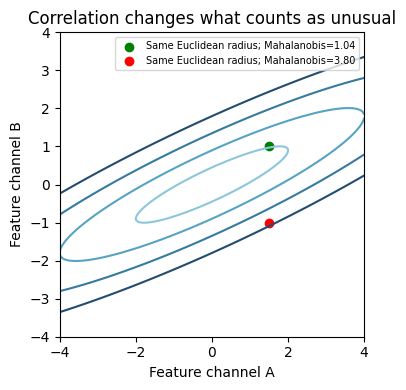

In [4]:
print(inspect.getsource(SpatialGaussian))
# Analytic two-dimensional illustration, unrelated to benchmark fitting/selection.
axis=np.linspace(-4,4,160)
xx,yy=np.meshgrid(axis,axis);grid=np.stack([xx,yy],-1)
covariance=np.array([[4.,1.8],[1.8,1.]])+.01*np.eye(2)
distances=np.sqrt(np.einsum('...i,ij,...j->...',grid,np.linalg.inv(covariance),grid))
fig,ax=plt.subplots(figsize=(5,4))
ax.contour(xx,yy,distances,levels=[1,2,3,4],colors=['#8dc6db','#56a3c3','#367b9f','#244c6e'])
for point,color in [(np.array([1.5,1.]),'green'),(np.array([1.5,-1.]),'red')]:
    distance=np.sqrt(point@np.linalg.solve(covariance,point))
    ax.scatter(*point,color=color,label=f'Same Euclidean radius; Mahalanobis={distance:.2f}')
ax.set(xlabel='Feature channel A',ylabel='Feature channel B',title='Correlation changes what counts as unusual',aspect='equal')
ax.legend(fontsize=7);fig.tight_layout();plt.show();plt.close(fig)

Full covariance captures correlations among shallow and deep channels. A
large distance signals an unusual direction after accounting for normal
variation. Scores are distances, not calibrated probabilities. Spatial alignment,
Gaussian assumptions and limited fit samples constrain the method.

## 5. Frozen normal partitions and data provenance

The existing seed-2026 70/15/15 normal partition manifests remain unchanged.
Fit estimates all Gaussians; development selects configuration using synthetic
proxies; reserved normals calibrate thresholds only after selection is frozen.

In [5]:
display(pd.DataFrame([dict(category=c,**{p:len(read_partition(p,c)) for p in ['fit','development','calibration','test']}) for c in CATEGORIES]))
fit_rows=read_partition('fit','bottle');dev_rows=read_partition('development','bottle')
require_fitting(fit_rows)
assert not set(fit_rows.path)&set(dev_rows.path)
print('Dataset validation SHA256:',sha256(ROOT/'reports/dataset_validation.json'))

,category,fit,development,calibration,test
0,bottle,147,31,31,83
1,cable,158,33,33,150
2,capsule,155,32,32,132
3,carpet,196,42,42,117
4,grid,186,39,39,78
5,hazelnut,275,58,58,110
6,leather,173,36,36,124
7,metal_nut,154,33,33,115
8,pill,187,40,40,167
9,screw,224,48,48,160


Dataset validation SHA256: dba510a81949afce789d9ce25a8dbe5d1a653d75e1c6669ecfd664cde63a2480


Earlier descriptive EDA saw test annotations. We therefore claim no test-label
tuning, not unseen test labels. Each category retains all official test normals
and defects; difficult categories are not omitted from macro results.

## 6. Preprocessing and paper fidelity

Use whole-image RGB PIL bilinear resize to 256 square, followed by the existing
V1 weight transform with identity resize/crop geometry and ImageNet mean/std.
The paper used 224 center cropping and bicubic interpolation. This exception
preserves shared geometry and keeps borders for model comparison.

In [6]:
images=load_resized(fit_rows.iloc[:24],256)
extractor=PaDiMExtractor(100,2026).cuda()
print('Input uint8:',tuple(images.shape))
print('Official weight transform with geometry override:',extractor.transform)
print('Weight SHA256:',extractor.weight_sha256)
assert extractor.weight_sha256==frozen['weight_sha256']

Input uint8: (24, 3, 256, 256)
Official weight transform with geometry override: ImageClassification(
    crop_size=[256]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Weight SHA256: f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec


There is no learned normalization from development, calibration or test
statistics. Whole-image resizing can distort aspect ratios. This shared geometry
and the held-out normal partitions prevent direct equality with paper numbers.

## 7. Frozen ResNet18 multiscale features

Layer1, layer2 and layer3 encode successively coarser context. We reuse the
verified frozen extractor; all parameters and BatchNorm statistics remain fixed.
Nearest alignment repeats coarse cells at the finest spatial grid.

In [7]:
with torch.inference_mode():
    raw=extractor.feature_maps(images[:1].cuda().float()/255)
    aligned=aligned_embedding(raw)
print('Layer shapes:',[tuple(x.shape) for x in raw])
print('Concatenated shape:',tuple(aligned.shape))
print(inspect.getsource(aligned_embedding))
assert not any(p.requires_grad for p in extractor.parameters())

Layer shapes:

 [(1, 64, 64, 64), (1, 128, 32, 32), (1, 256, 16, 16)]
Concatenated shape: (1, 448, 64, 64)
def aligned_embedding(maps):
    """Nearest alignment preserves each coarse cell, then concatenates channels."""
    if len(maps) != 3 or any(x.ndim != 4 or x.shape[0] != maps[0].shape[0] for x in maps):
        raise ValueError('Three matching B,C,H,W batches required')
    return torch.cat([F.interpolate(x, size=maps[0].shape[-2:], mode='nearest') for x in maps], 1)



The measured 448-channel embedding joins 64, 128 and 256 channels at a
64-square grid. There is no PatchCore 3x3 local pooling. One Gaussian belongs
to each of 4096 positions, preserving correlations across all selected levels.

## 8. Seeded dimensionality reduction

Uniform channel sampling without replacement reduces covariance storage and
fitting cost. A single subset is fixed for every image and location of a model.
Only the channel subset changes across the three final model seeds.

In [8]:
features=extract(extractor,images)
print('Selected fit tensor:',tuple(features.shape))
print('First selected channel indices:',extractor.indices[:20].cpu().tolist())
assert extractor.indices.unique().numel()==100
print(inspect.getsource(PaDiMExtractor))

Selected fit tensor: (24, 100, 64, 64)
First selected channel indices: [0, 1, 14, 26, 28, 31, 32, 35, 37, 42, 49, 50, 56, 65, 69, 70, 73, 82, 92, 94]
class PaDiMExtractor(PatchExtractor):
    """Reuse verified V1 weights/normalization; no PatchCore local pooling."""
    def __init__(self, dimension=100, seed=2026, pretrained=True):
        super().__init__(pretrained)
        if not 1 <= dimension <= 448:
            raise ValueError('Dimension must be in [1,448]')
        indices = torch.randperm(448, generator=torch.Generator().manual_seed(seed))[:dimension].sort().values
        self.register_buffer('indices', indices)

    @torch.inference_mode()
    def forward(self, images):
        return aligned_embedding(self.feature_maps(images)).index_select(1, self.indices)



Persistent covariance storage scales as positions times dimension squared.
With dimension 100 this is about 164 MB in float32, plus means. Inference cost
is independent of the number of fit normals once Gaussian parameters are saved.

## 9. Live normal-only Gaussian estimation

This cell performs an explicit normal-only replay using the same first 24 fit
images as the pilot. It is a mathematical demonstration, not a new final fit or
benchmark. Spatial blocking bounds covariance construction and solve workspace.

In [9]:
torch.cuda.synchronize();started=time.perf_counter()
gaussian=SpatialGaussian(.01).fit(features,'cuda')
torch.cuda.synchronize()
print('Live demonstration fitting seconds:',time.perf_counter()-started)
print('Mean / Cholesky:',tuple(gaussian.mean.shape),tuple(gaussian.cholesky.shape))
print('Minimum Cholesky diagonal:',float(gaussian.cholesky.diagonal(dim1=-2,dim2=-1).min()))

Live demonstration fitting seconds: 0.16542439998011105
Mean / Cholesky: (4096, 100) (4096, 100, 100)
Minimum Cholesky diagonal: 0.10000000149011612


The sample covariance uses the unbiased N-1 denominator and fixed additive
0.01 identity regularization. Cholesky factors avoid an explicit matrix inverse.
Regularization also makes low-sample and constant-feature covariances solvable.

## 10. Live held-out normal scoring and map construction

Eight development normals are scored here through triangular solves, bilinear
upsampling and fixed sigma-4 Gaussian smoothing. Multiple right-hand sides avoid
repeating a full covariance tensor for every image in a scoring batch.

In [10]:
dev_features=extract(extractor,load_resized(dev_rows.iloc[:8],256))
development_maps=score(gaussian,dev_features)
live_scores=development_maps.flatten(1).max(1).values.numpy()
print('Map shape:',tuple(development_maps.shape))
print('Image maxima:',live_scores)
assert torch.isfinite(development_maps).all()
print(inspect.getsource(anomaly_maps))

Map shape: (8, 256, 256)
Image maxima: [14.398673 12.218349 13.838648 12.565697 10.278752  9.646579 17.18949
 10.881905]
def anomaly_maps(distances, sigma=4.):
    """Bilinear 256-square maps, optional separable Gaussian with reflect edges."""
    maps = F.interpolate(distances[:, None], size=(256, 256), mode='bilinear', align_corners=False)
    if sigma:
        radius = int(4*sigma+.5)
        axis = torch.arange(-radius, radius+1, device=maps.device, dtype=maps.dtype)
        kernel = torch.exp(-axis.square()/(2*sigma*sigma)); kernel /= kernel.sum()
        maps = F.conv2d(F.pad(maps, (radius, radius, 0, 0), mode='reflect'), kernel[None,None,None,:])
        maps = F.conv2d(F.pad(maps, (0, 0, radius, radius), mode='reflect'), kernel[None,None,:,None])
    return maps[:, 0]



Higher distances mean more anomalous. Image scores are maxima of the smoothed
256-square map, fixed before real-test access. Native interpolation is applied
only to continuous maps; the original binary masks remain at native resolution.

## 11. Numerical correctness evidence

Tests compare independent float64 covariance solves, constant singular inputs,
multiple right-hand sides, CPU/GPU parity, seeded selection, serialization,
category checking and smoothing. A tiny synthetic native evaluator fixture also
checks image-resize restoration and exact ranking/region metrics independently.

In [11]:
print((ROOT/'tests/test_padim.py').read_text())
print('Recorded suite evidence:',json.loads((report/'validation.json').read_text())['tests'])

import numpy as np
import pytest
import torch
from scipy.ndimage import gaussian_filter
from anomaly_detection.padim import SpatialGaussian, PaDiMExtractor, aligned_embedding, anomaly_maps


def test_spatial_covariance_and_distances_against_float64_reference(tmp_path):
    x = torch.randn(17, 4, 2, 3, generator=torch.Generator().manual_seed(19))
    q = torch.randn(3, 4, 2, 3, generator=torch.Generator().manual_seed(20))
    model = SpatialGaussian(.01, block=2).fit(x)
    actual = model.score(q)
    for i in range(2):
        for j in range(3):
            values = x[:, :, i, j].double()
            covariance = torch.cov(values.T) + .01*torch.eye(4, dtype=torch.float64)
            delta = q[:, :, i, j].double() - values.mean(0)
            expected = (delta * torch.linalg.solve(covariance, delta.T).T).sum(1).sqrt()
            torch.testing.assert_close(actual[:, i, j].double(), expected, atol=2e-5, rtol=2e-5)
    path = tmp_path/'gaussian.pt'
    model.save(path, 'bottle', {'seed':

These tests establish implementation correctness on known fixtures. The real
normal-image pilot separately establishes pretrained feature extraction and GPU
resource feasibility. Neither test suite nor synthetic proxy quality establishes
benchmark detection performance by itself.

## 12. Actual real-data GPU pilot record

The original registered pilot ran before development and final evaluation.
This cell reads that immutable measurement; the live demonstration timings above
are separate executions. The pilot required finite scores and bounded resources.

In [12]:
pilot=json.loads((report/'runs/05-pilot-bottle-s2026-v1-result.json').read_text())
display(pd.Series(pilot))
np.testing.assert_allclose(live_scores,pilot['image_scores'],rtol=1e-5,atol=1e-5)
assert pilot['passed']

configuration                  {'dimension': 100, 'epsilon': 0.01, 'sigma': 4...
raw_layer_shapes               [[1, 64, 64, 64], [1, 128, 32, 32], [1, 256, 1...
selected_fit_shape                                             [24, 100, 64, 64]
extraction_seconds                                                      0.304797
gaussian_fit_seconds                                                    0.179153
development_scoring_seconds                                              0.18589
resources                      {'seconds': 0.9740356999973301, 'cpu_initial_r...
score_min                                                               0.149266
score_max                                                              17.189489
image_score_quantiles          [9.646578788757324, 10.731116533279419, 12.392...
image_scores                   [14.398673057556152, 12.21834945678711, 13.838...
fit_source_sha256              f48bab0865cfd6655ce4e749466ead30fd5bdf88fe408f...
development_source_sha256   

The pilot used 24 actual bottle fitting normals and eight development normals.
Its raw and selected feature shapes, extraction/fitting/scoring duration, RSS,
VRAM and score statistics are recorded rather than estimated. Passing this gate
authorized the bounded study under the predeclared research protocol.

## 13. All bounded development experiments

Four configurations vary dimension 50/100 and epsilon 0.01/0.1 over bottle,
cable, carpet and tile. The inner 20% fit holdout supplies identical synthetic
probes; reserved development normals supply diagnostic q95 thresholds. Probe
sources never enter the fitted Gaussian used for this development comparison.

In [13]:
development=[json.loads(p.read_text()) for p in sorted((report/'runs').glob('05-dev-*-result.json'))]
display(pd.DataFrame([dict(category=r['category'],**r['configuration'],proxy_image_auroc=r['proxy_image_auroc'],proxy_pixel_ap=r['proxy_pixel_ap'],objective=r['selection_objective'],proxy_recall=r['proxy_recall'],normal_development_fpr=r['development_fpr']) for r in development]))
display(pd.DataFrame(frozen['development']))
print('All registered candidates:',len(development))

,category,dimension,epsilon,sigma,seed,resolution,proxy_image_auroc,proxy_pixel_ap,objective,proxy_recall,normal_development_fpr
0,bottle,100,0.01,4.0,2026,256,1.000000,0.831740,0.915870,1.000000,0.032258
1,cable,100,0.01,4.0,2026,256,0.876171,0.491805,0.683988,0.129032,0.030303
2,carpet,100,0.01,4.0,2026,256,0.867850,0.499030,0.683440,0.666667,0.047619
3,tile,100,0.01,4.0,2026,256,0.723633,0.439233,0.581433,0.500000,0.029412
4,bottle,100,0.10,4.0,2026,256,1.000000,0.841625,0.920813,1.000000,0.032258
5,cable,100,0.10,4.0,2026,256,0.827263,0.347871,0.587567,0.064516,0.030303
6,carpet,100,0.10,4.0,2026,256,0.832347,0.479984,0.656166,0.615385,0.047619
7,tile,100,0.10,4.0,2026,256,0.717285,0.417415,0.567350,0.468750,0.029412
8,bottle,50,0.01,4.0,2026,256,1.000000,0.830187,0.915093,1.000000,0.032258
9,cable,50,0.01,4.0,2026,256,0.777315,0.304921,0.541118,0.064516,0.030303


,dimension,epsilon,objective
0,50,0.01,0.678782
1,50,0.10,0.646323
2,100,0.01,0.716183
3,100,0.10,0.682974


All registered candidates: 16


The selected mean synthetic objective favors dimension 100 and epsilon 0.01.
Cable and tile proxy performance is weaker than bottle; these results remain
in the record. No new configuration was added in response to final-test scores.

## 14. Prospective configuration freeze

Before calibration or test access, freeze dimensions, covariance policy,
smoothing, image aggregation, source identities, weight checksum, environment,
dataset validation and all three seeds. The running evaluator checks these hashes
before each category/seed so accidental source changes stop execution.

In [14]:
from anomaly_detection.padim_evaluation import verify_freeze
verified,identity=verify_freeze()
assert identity==summary['frozen_configuration_sha256']
print(json.dumps(verified,indent=2))

{
  "configuration": {
    "dimension": 100,
    "epsilon": 0.01,
    "sigma": 4.0,
    "resolution": 256
  },
  "seeds": [
    2026,
    2027,
    2028
  ],
  "categories": [
    "bottle",
    "cable",
    "capsule",
    "carpet",
    "grid",
    "hazelnut",
    "leather",
    "metal_nut",
    "pill",
    "screw",
    "tile",
    "toothbrush",
    "transistor",
    "wood",
    "zipper"
  ],
  "development": [
    {
      "dimension": 50,
      "epsilon": 0.01,
      "objective": 0.6787820386395036
    },
    {
      "dimension": 50,
      "epsilon": 0.1,
      "objective": 0.6463229927479832
    },
    {
      "dimension": 100,
      "epsilon": 0.01,
      "objective": 0.7161825818093985
    },
    {
      "dimension": 100,
      "epsilon": 0.1,
      "objective": 0.6829739048710686
    }
  ],
  "source_sha256": {
    "src/anomaly_detection/padim.py": "733a4a9c5fa7d5522bb1aaa5326b009b68179fb88ac75492be25d9bb32ceb92a",
    "src/anomaly_detection/padim_research.py": "c28628965a7f9ce512d

The recorded Git base was the completed Milestone 6 commit with new PaDiM
files still uncommitted. Exact source hashes identify the evaluated implementation
despite that dirty worktree. Publication happens only after artifact validation.

## 15. Final fitting and checkpoint provenance

Every final Gaussian uses all fit normals from one category and its own seeded
channel subset. Checkpoints retain category, configuration, Gaussian parameters
and fit-source identity. This artifact-analysis cell loads a completed checkpoint;
it does not refit it or re-evaluate official test images.

In [15]:
first=json.loads((report/'evaluation/05-test-bottle-s2026-v1-result.json').read_text())
assert sha256(ROOT/first['checkpoint'])==first['checkpoint_sha256']
restored,saved=SpatialGaussian.load(ROOT/first['checkpoint'],'bottle')
print('Saved category:',saved['category'],'configuration:',saved['configuration'])
print('Fit provenance:',saved['provenance'])
runs=pd.read_csv(report/'all_runs.csv')
display(runs[['category','seed','training_seconds','checkpoint_bytes','train_peak_vram_gib']])
del restored

Saved category: bottle configuration: {'dimension': 100, 'epsilon': 0.01, 'sigma': 4.0, 'resolution': 256, 'seed': 2026}
Fit provenance: {'phase': 'final', 'fit_source_sha256': 'a30d1eb8078d22e75ef8e9b61ce7b508b283b31c743556cf1b004027fe17d7ab', 'freeze_sha256': '8076545431166828cb606acead31d163aee80297a06ce174b4494a682b0053ad'}


,category,seed,training_seconds,checkpoint_bytes,train_peak_vram_gib
0,bottle,2026,0.927923,165480613,0.372108
1,cable,2026,0.820437,165480613,0.370527
2,capsule,2026,0.703787,165480613,0.372034
3,carpet,2026,0.984803,165480613,0.377393
4,grid,2026,0.901426,165480613,0.373334
5,hazelnut,2026,1.256888,165480613,0.382101
6,leather,2026,0.777112,165480613,0.372335
7,metal_nut,2026,0.682798,165480613,0.370885
8,pill,2026,0.831690,165480613,0.373292
9,screw,2026,1.017821,165480613,0.377859


All 45 checkpoints are retained locally under checkpoints/padim and excluded
from Git. Gaussian storage is larger than small learned heads, but inference
requires no stored normal-image memory bank. Shared ImageNet weights are reused.

## 16. Normal-only calibration and threshold uncertainty

Thresholds are set from reserved real normals after the model is fixed. Image
alarms use the higher empirical q95 and strict greater-than. Pixels use a separate
pooled q99.5 at 256 square. A nominal target is not a population FPR guarantee.

,category,seed,calibration_images,image_threshold,pixel_threshold,recall,fpr
0,bottle,2026,31,11.176394,7.999887,1.000000,0.300000
1,cable,2026,33,22.236214,12.600834,0.293478,0.034483
2,capsule,2026,32,17.018772,8.813929,0.642202,0.086957
3,carpet,2026,42,11.154517,7.667648,0.898876,0.035714
4,grid,2026,39,11.573739,9.087839,0.385965,0.047619
5,hazelnut,2026,58,17.162186,12.517488,0.857143,0.250000
6,leather,2026,36,10.258766,7.364798,1.000000,0.062500
7,metal_nut,2026,33,15.058509,11.062572,0.881720,0.090909
8,pill,2026,40,17.051636,10.633986,0.319149,0.038462
9,screw,2026,48,20.063032,14.191308,0.100840,0.024390


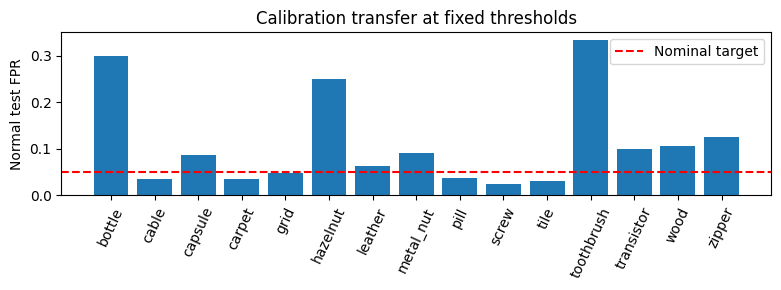

In [16]:
calibration=first['calibration']
assert float(np.quantile(calibration['scores'],.95,method='higher'))==calibration['image_threshold']
display(runs[['category','seed','calibration_images','image_threshold','pixel_threshold','recall','fpr']])
fig,ax=plt.subplots(figsize=(8,3))
selected=runs[runs.seed.eq(2026)]
ax.bar(selected.category,selected.fpr);ax.axhline(.05,color='red',linestyle='--',label='Nominal target')
ax.set(ylabel='Normal test FPR',title='Calibration transfer at fixed thresholds');ax.tick_params(axis='x',rotation=65);ax.legend();fig.tight_layout();plt.show();plt.close(fig)

Calibration samples can be small and unrepresentative of test normals. Report
actual false alarms with recall, even when AUROC is high. Bootstrap intervals
condition on the fitted models and frozen thresholds and exclude calibration
sampling uncertainty; seed standard deviation measures a different variation.

## 17. Complete native benchmark and uncertainty

Each official test category was evaluated once for each registered seed.
Ranking metrics use raw distances and original-resolution masks. Exact pixel
point metrics use a memory-bounded native sweep; pixel bootstrap intervals use
4096 calibration-scaled bins and resample whole images, not independent pixels.

In [17]:
display(pd.DataFrame(summary['macro']).T)
display(pd.read_csv(report/'all_category_means.csv'))
display(pd.read_csv(report/'macro_by_seed.csv'))
display(pd.DataFrame(summary['pixel_bootstrap_quantization_bias']).T)
assert len(runs)==45 and runs.groupby('category').size().eq(3).all()

,mean,seed_std,image_bootstrap_95ci,bootstrap_target
image_auroc,0.897933,0.007678,"[0.8789845045809254, 0.9158594732607404]","exact image metric, fixed fitted models/thresh..."
image_ap,0.946389,0.003356,"[0.9341845182125459, 0.9592080475095746]","exact image metric, fixed fitted models/thresh..."
pixel_auroc,0.96592,0.001314,"[0.9626622431273472, 0.9694243161292442]",4096-bin calibration-scaled pixel approximation
pixel_ap,0.453764,0.020768,"[0.4357236095632135, 0.4723762314253988]",4096-bin calibration-scaled pixel approximation
au_pro,0.911929,0.003998,"[0.9054246615655347, 0.9180624610762464]",4096-bin calibration-scaled pixel approximation
recall,0.696493,0.045293,"[0.6789027969187057, 0.714150709647356]","exact image metric, fixed fitted models/thresh..."
fpr,0.144521,0.035187,"[0.11509630961671921, 0.17471192870174782]","exact image metric, fixed fitted models/thresh..."
precision,0.925512,0.011029,"[0.908105803996494, 0.9423705461499535]","exact image metric, fixed fitted models/thresh..."
f1,0.755358,0.030319,"[0.7374512809096904, 0.7702979019978489]","exact image metric, fixed fitted models/thresh..."


,category,image_auroc_mean,image_auroc_std,image_ap_mean,image_ap_std,pixel_auroc_mean,pixel_auroc_std,pixel_ap_mean,pixel_ap_std,au_pro_mean,au_pro_std,recall_mean,recall_std,fpr_mean,fpr_std,precision_mean,precision_std,f1_mean,f1_std
0,bottle,0.996825,0.002100,0.999003,0.000651,0.983087,0.001708,0.722268,0.018797,0.951034,0.004348,1.000000,0.000000,0.333333,0.104083,0.904838,0.026698,0.949904,0.014806
1,cable,0.834770,0.025689,0.875193,0.021761,0.963631,0.002537,0.381467,0.004252,0.892060,0.004097,0.275362,0.016604,0.028736,0.009954,0.938550,0.020302,0.425596,0.019817
2,capsule,0.882861,0.015212,0.961668,0.007691,0.984442,0.000761,0.403927,0.022817,0.933608,0.003154,0.574924,0.074155,0.101449,0.025102,0.963911,0.008505,0.718433,0.059958
3,carpet,0.971241,0.015198,0.991444,0.004322,0.988394,0.001289,0.555411,0.057922,0.960183,0.006032,0.925094,0.028277,0.083333,0.054554,0.972967,0.016536,0.948070,0.006940
4,grid,0.816764,0.024533,0.926770,0.007102,0.919817,0.009229,0.189635,0.017246,0.799890,0.017039,0.532164,0.182602,0.126984,0.099127,0.927058,0.031640,0.661866,0.132160
5,hazelnut,0.834881,0.060710,0.862188,0.045047,0.977841,0.004149,0.488541,0.061303,0.933176,0.004279,0.871429,0.093678,0.366667,0.125831,0.808991,0.043445,0.836423,0.039062
6,leather,0.998755,0.002157,0.999547,0.000785,0.992198,0.000544,0.422608,0.030161,0.981721,0.000443,0.996377,0.006276,0.072917,0.047735,0.975396,0.015666,0.985700,0.006043
7,metal_nut,0.952428,0.017679,0.987924,0.005101,0.967769,0.003000,0.725937,0.014039,0.918503,0.006477,0.845878,0.122285,0.136364,0.078730,0.964338,0.015925,0.897555,0.067989
8,pill,0.872159,0.019763,0.970925,0.004965,0.951061,0.005737,0.455481,0.051093,0.936744,0.004503,0.394799,0.143489,0.038462,0.038462,0.984523,0.013484,0.553462,0.137224
9,screw,0.766209,0.037782,0.891839,0.024799,0.976758,0.001612,0.154723,0.038821,0.917878,0.003140,0.159664,0.087734,0.032520,0.037257,0.944947,0.048011,0.265858,0.121549


,seed,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,2026,0.902637,0.949216,0.965320,0.439455,0.910319,0.688858,0.110996,0.938053,0.753922
1,2027,0.902089,0.947271,0.967427,0.477584,0.916481,0.745118,0.181163,0.917323,0.786368
2,2028,0.889072,0.942681,0.965014,0.444253,0.908987,0.655503,0.141406,0.921160,0.725782


,mean_binned_minus_exact,maximum_absolute_run_difference
pixel_auroc,-1.993226e-07,0.000001
pixel_ap,-2.731149e-04,0.000586
au_pro,-5.316607e-07,0.000005


Macro means weight categories equally. Pixel AP remains prevalence-sensitive;
AU-PRO gives equal weight to 8-connected real defect regions over background FPR
0–0.30. The binned-minus-exact diagnostic quantifies the approximation in pixel
uncertainty; the primary point estimates are always exact native metrics.

## 18. Comparison against all four completed models

Use precise stored results for Basic CNN, autoencoder, PatchCore variant and
SuperSimpleNet Lite. Paired image intervals use identical category/seed/image
resamples and fixed fitted models. Inspect detection, localization, recall, FPR
and runtime together rather than treating AUROC as the sole outcome.

,Basic CNN,Autoencoder,PatchCore variant,SuperSimpleNet Lite,PaDiM
image_auroc,0.712589,0.634623,0.967572,0.964783,0.897933
image_ap,0.858954,0.827916,0.988538,0.986239,0.946389
pixel_auroc,0.785832,0.690002,0.972944,0.952850,0.965920
pixel_ap,0.235382,0.110897,0.540154,0.436077,0.453764
au_pro,0.549807,0.449350,0.920399,0.856502,0.911929
recall,0.401760,0.235000,0.890435,0.892012,0.696493
fpr,0.098341,0.093944,0.171806,0.166249,0.144521
precision,0.873299,0.789620,0.940045,0.941235,0.925512
f1,0.510593,0.314635,0.904345,0.909892,0.755358


,comparison,metric,point_difference,low,high,method
0,Basic CNN,image_auroc,0.185344,0.162027,0.207583,Paired category/seed/image bootstrap; 2000 sam...
1,Basic CNN,image_ap,0.087435,0.070948,0.100358,Paired category/seed/image bootstrap; 2000 sam...
2,Basic CNN,recall,0.294734,0.271870,0.318172,Paired category/seed/image bootstrap; 2000 sam...
3,Basic CNN,fpr,0.046181,0.014077,0.078089,Paired category/seed/image bootstrap; 2000 sam...
4,Basic CNN,precision,0.052213,0.023324,0.093406,Paired category/seed/image bootstrap; 2000 sam...
5,Basic CNN,f1,0.244765,0.221993,0.267992,Paired category/seed/image bootstrap; 2000 sam...
6,Autoencoder,image_auroc,0.263310,0.234194,0.291662,Paired category/seed/image bootstrap; 2000 sam...
7,Autoencoder,image_ap,0.118473,0.097700,0.134285,Paired category/seed/image bootstrap; 2000 sam...
8,Autoencoder,recall,0.461493,0.437442,0.484532,Paired category/seed/image bootstrap; 2000 sam...
9,Autoencoder,fpr,0.050577,0.015471,0.085468,Paired category/seed/image bootstrap; 2000 sam...


,model,model_p50_ms,end_to_end_p50_ms
0,Basic CNN,3.139279,12.538484
1,Autoencoder,2.870592,13.272136
2,PatchCore variant,15.338837,33.577510
3,SuperSimpleNet Lite,9.688543,28.793411
4,PaDiM,12.930138,20.692256


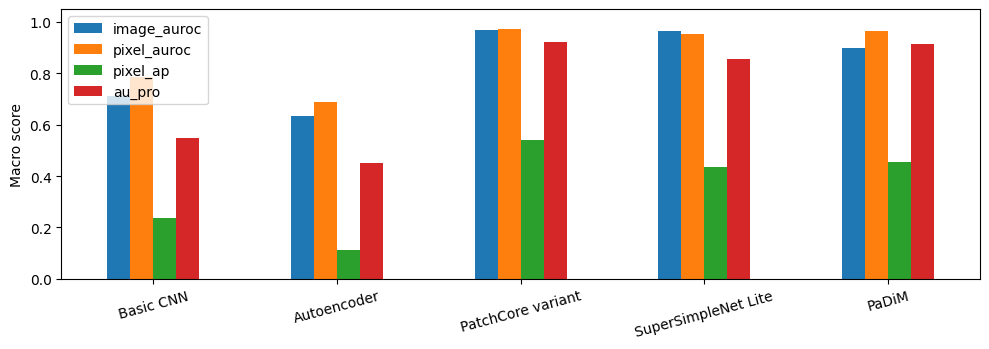

In [18]:
comparison=pd.read_csv(report/'model_macro_comparison.csv',index_col=0)
display(comparison)
display(pd.read_csv(report/'paired_image_difference_intervals.csv'))
display(pd.read_csv(report/'model_latency_comparison.csv'))
fig,ax=plt.subplots(figsize=(10,3.6))
comparison.loc[['image_auroc','pixel_auroc','pixel_ap','au_pro']].T.plot.bar(ax=ax)
ax.set(ylim=(0,1.05),ylabel='Macro score');ax.tick_params(axis='x',rotation=15);fig.tight_layout();plt.show();plt.close(fig)

These comparisons describe this benchmark and its implementation/budget
choices. A deployment choice informed by these test results would need independent
confirmation data. Geometry and training budgets differ from original papers,
so literature scores are context rather than interchangeable baselines.

## 19. Retrospective failure and small-defect analysis

The following diagnostic tables are generated only after all confirmations.
They retain threshold errors, mask-area strata and defect types. This analysis
cannot change hyperparameters or thresholds. The displayed example policy uses
strongest FP and weakest FN margins at seed 2026, with successful controls.

,category,outcome,defect,score_minus_threshold,defect_fraction
0,bottle,FP,good,5.796381,0.000000
1,bottle,TP,contamination,41.496356,0.006702
2,bottle,TN,good,-4.315715,0.000000
3,cable,FP,good,3.302158,0.000000
4,cable,FN,missing_wire,-9.872544,0.023795
5,cable,TP,bent_wire,12.797599,0.113708
6,cable,TN,good,-11.623871,0.000000
7,capsule,FP,good,10.272980,0.000000
8,capsule,FN,poke,-6.770909,0.002743
9,capsule,TP,crack,20.247631,0.004812


,size_stratum,images_across_seeds,detected,mean_score,recall
0,<=0.1%,51,32,18.547859,0.627451
1,0.1-1%,1446,788,18.543502,0.544952
2,1-5%,1548,1051,19.815235,0.678941
3,>5%,729,553,21.180213,0.758573


,kind,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,object,0.873213,0.929727,0.974552,0.490366,0.924499,0.630408,0.173892,0.905973,0.693472
1,texture,0.947372,0.979714,0.948657,0.380560,0.886790,0.828663,0.085780,0.964589,0.879129


,category,defect,images_across_seeds,recall,mean_defect_fraction
49,screw,thread_side,69,0.028986,0.002798
4,cable,cable_swap,36,0.055556,0.057958
50,screw,thread_top,69,0.057971,0.005125
8,cable,missing_cable,36,0.083333,0.102658
47,screw,scratch_head,72,0.083333,0.002477
69,zipper,fabric_interior,48,0.125000,0.018396
9,cable,missing_wire,30,0.133333,0.022060
42,pill,crack,78,0.166667,0.007783
10,cable,poke_insulation,30,0.166667,0.023898
48,screw,scratch_neck,75,0.226667,0.003316


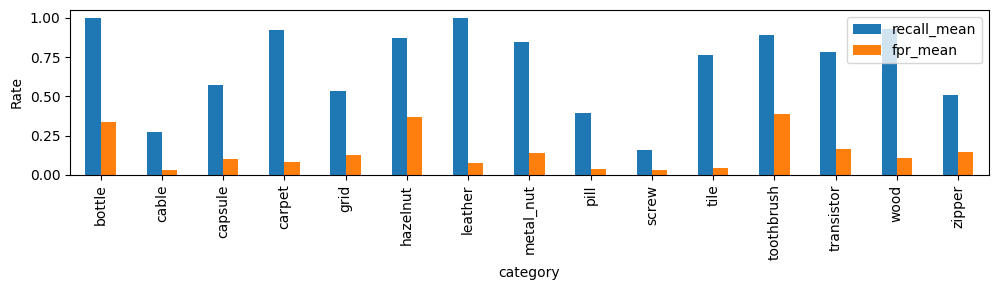

In [19]:
examples=pd.read_csv(report/'failure_examples.csv')
display(examples[['category','outcome','defect','score_minus_threshold','defect_fraction']])
display(pd.read_csv(report/'small_defect_summary.csv'))
display(pd.read_csv(report/'texture_object.csv'))
display(pd.read_csv(report/'defect_type_size_summary.csv').sort_values('recall').head(20))
fig,ax=plt.subplots(figsize=(10,3))
category_means=pd.read_csv(report/'all_category_means.csv').set_index('category')
category_means[['recall_mean','fpr_mean']].plot.bar(ax=ax);ax.set(ylabel='Rate',ylim=(0,1.05));fig.tight_layout();plt.show();plt.close(fig)

These retrospective strata do not establish causality. Small defects may be
diluted by receptive fields and smoothing; object misalignment may violate
spatial Gaussian assumptions. No resolution, alignment or smoothing counterfactual
was run, so those explanations remain hypotheses rather than measured causes.

### Local qualitative failure panels

These licensed original-image panels remain only in the full local executed
notebook and ignored output directory. Public output is cleared for this cell.
Cases are selected by the already declared error-margin policy, with no new
threshold or model selection. Each map uses its own raw distance color scale.

In [20]:
from PIL import Image
data_root=autodiscover_data_root(ROOT)
chosen=[]
for category in ['bottle','cable','screw']:
    group=examples[examples.category.eq(category)]
    for outcome in ['FP','FN','TP']:
        subset=group[group.outcome.eq(outcome)]
        if not len(subset) and outcome=='FN':subset=group[group.outcome.eq('TN')]
        if len(subset):chosen.append(subset.iloc[0])
fig,axes=plt.subplots(len(chosen),4,figsize=(12,2.8*len(chosen)),squeeze=False)
for row,axs in zip(chosen,axes):
    with Image.open(data_root/row.path) as image:rgb=np.asarray(image.convert('RGB'))
    if isinstance(row['mask'],str):
        with Image.open(data_root/row['mask']) as image:truth=np.asarray(image)>0
    else:truth=np.zeros(rgb.shape[:2],bool)
    small=np.load(ROOT/row.maps_path,mmap_mode='r')[int(row.row_index)]
    native=torch.nn.functional.interpolate(torch.from_numpy(np.array(small))[None,None],size=rgb.shape[:2],mode='bilinear',align_corners=False).numpy()[0,0]
    axs[0].imshow(rgb);axs[0].set_title(f'{row.category}: {row.outcome} ({row.defect})',fontsize=9)
    axs[1].imshow(truth,cmap='gray');axs[1].set_title('Original binary annotation')
    axs[2].imshow(native,cmap='inferno');axs[2].set_title(f'Image margin {row.score_minus_threshold:.2f}')
    axs[3].imshow(rgb);axs[3].imshow(np.ma.masked_where(native<=row.pixel_threshold,native),cmap='autumn',alpha=.6);axs[3].set_title('Frozen pixel threshold overlay')
    for ax in axs:ax.axis('off')
fig.tight_layout();fig.savefig(ROOT/'outputs/padim/failure-panels.png',dpi=110)
plt.show();plt.close(fig)

The same original mask geometry is used for scoring and visual inspection.
The overlay threshold is separately calibrated on normal pixels. A visually
bright map is not a probability estimate, and these selected cases are qualitative
examples rather than a representative random sample of benchmark outcomes.

### Observed panel review after confirmation

Bottle's false positive concentrates on the normal interior; its contamination control responds at the foreign object. Cable's missing-wire false negative has no frozen-threshold overlay, while the bent-wire true positive broadly covers the displaced wires. Screw's scratch-neck false negative does not alarm; its manipulated-front true positive responds near the damaged tip, with extra border responses. Per-image color scales make bright maps incomparable across examples. See the [visual review](../reports/padim/observed_panel_analysis.md). These are selected observations and do not isolate the causes of aggregate errors.

## 20. Resources, limitations and reproducibility

Latency uses 50 warmups and 200 synchronized batch-one float32 iterations.
Feature extraction and Gaussian scoring form model time; smoothing, native
interpolation and CPU transfer are postprocessing. Fit and evaluation resources
are recorded separately. Local licensed images and large arrays are not published.

In [21]:
display(pd.Series({k:v for k,v in summary.items() if k!='macro'}))
display(Markdown((report/'findings.md').read_text()))
display(Markdown((ROOT/'docs/padim_reproduction.md').read_text()))
del extractor,gaussian,features,dev_features,raw,aligned
torch.cuda.empty_cache()

categories                                                                                        15
seeds                                                                             [2026, 2027, 2028]
models                                                                                            45
development_runs                                                                                  16
frozen_backbone_parameters                                                                   2782784
trainable_backbone_parameters                                                                      0
spatial_gaussians                                                                               4096
gaussian_dimension                                                                               100
independent_gaussian_mean_covariance_parameters                                             21094400
stored_gaussian_float32_values                                                             

# PaDiM findings

All 15 categories completed across seeds 2026, 2027 and 2028 (45 category-specific models). The real GPU pilot and 16 bounded development runs preceded the frozen confirmation. No hyperparameter or threshold changed after official test access.

## Selected method

Frozen ImageNet V1 ResNet18 layer1/2/3 features, nearest alignment to 64 square, 100 seeded channels from 448, position-specific unbiased full covariances + 0.01 I, Cholesky Mahalanobis distances, bilinear 256-square maps and Gaussian sigma 4. Image score is maximum smoothed map. The selected four-category synthetic objective was 0.716183. Synthetic proxies are not real defects.

The shared whole-image 256-square bilinear geometry differs from the paper's 224 center crop and bicubic interpolation; we use three separate seeds rather than a ten-model score ensemble. Report these as shared-protocol PaDiM results, not a direct reproduction of the publication.

## Measured macro results

| Metric | Mean | Seed SD | Conditional image-bootstrap 95% interval |
|---|---:|---:|---|
| image_auroc | 0.897933 | 0.007678 | [0.878985, 0.915859] |
| image_ap | 0.946389 | 0.003356 | [0.934185, 0.959208] |
| pixel_auroc | 0.965920 | 0.001314 | [0.962662, 0.969424] |
| pixel_ap | 0.453764 | 0.020768 | [0.435724, 0.472376] |
| au_pro | 0.911929 | 0.003998 | [0.905425, 0.918062] |
| recall | 0.696493 | 0.045293 | [0.678903, 0.714151] |
| fpr | 0.144521 | 0.035187 | [0.115096, 0.174712] |
| precision | 0.925512 | 0.011029 | [0.908106, 0.942371] |
| f1 | 0.755358 | 0.030319 | [0.737451, 0.770298] |

Primary pixel metrics are exact at native resolution. Pixel intervals use whole-image resampling of 4096-bin calibration-scaled histograms; image metric intervals are exact conditional on fitted models and fixed thresholds. Seed SD and calibration-sampling uncertainty are distinct. The summary retains binned-minus-exact point differences as an approximation diagnostic.

## Comparison with all four earlier models

| Model | Image AUROC | Pixel AUROC | Pixel AP | AU-PRO | Recall | FPR |
|---|---:|---:|---:|---:|---:|---:|
| Basic CNN | 0.712589 | 0.785832 | 0.235382 | 0.549807 | 0.401760 | 0.098341 |
| Autoencoder | 0.634623 | 0.690002 | 0.110897 | 0.449350 | 0.235000 | 0.093944 |
| PatchCore variant | 0.967572 | 0.972944 | 0.540154 | 0.920399 | 0.890435 | 0.171806 |
| SuperSimpleNet Lite | 0.964783 | 0.952850 | 0.436077 | 0.856502 | 0.892012 | 0.166249 |
| PaDiM | 0.897933 | 0.965920 | 0.453764 | 0.911929 | 0.696493 | 0.144521 |

Paired category/seed/image bootstrap differences for every previous model are retained in paired_image_difference_intervals.csv. These are conditional benchmark comparisons, not a deployment generalization claim.

## Threshold errors and localization limits

The weakest category recalls were screw (0.160), cable (0.275), pill (0.395). The largest normal test FPRs were toothbrush (0.389), hazelnut (0.367), bottle (0.333). The higher empirical normal q95 calibration target does not guarantee a 5% test or population false-alarm rate. Small calibration sets and changed normal variation can produce substantial threshold errors even when ranking is good.

All per-defect results, pixel operating points, category/seed predictions and confusion counts remain available. Mask-area strata and low-recall defect types are retrospective descriptions; repeated images across three seeds are identified as such. Licensed strongest-FP/weakest-FN panels stay local. Spatial Gaussian mismatch, normal multimodality and smoothing of small defects are plausible limitations; no counterfactual isolates their causes.

## Measured resources

Total extraction + Gaussian fit time: 35.81s across all 45 models. Mean category/seed batch-one model p50/p95: 12.930/16.401 ms; end-to-end p50/p95: 20.692/25.042 ms. These are means of per-run quantiles, not pooled quantiles. Timing uses 50 warmups and 200 synchronized iterations; file decode is excluded. Model time contains feature extraction + Gaussian scoring; smoothing/native restoration are postprocessing.

Peak fitting allocated VRAM: 0.384 GiB; peak inference allocated VRAM: 0.232 GiB; peak evaluation process RSS: 7.000 GiB. Maximum Gaussian checkpoint: 165,480,613 bytes. Shared frozen ImageNet weights are stored separately. No fit-time feature cache hides the repeated per-seed extraction cost; existing resized RGB caches may be reused. Native metric sweeps dominate evaluation cost.

## Scope and next work

Milestones 1â€“6 are preserved. This milestone completes PaDiM only. EfficientAD has not been started. A future family comparison or deployment choice needs its own authorized stage and independent confirmation for claims beyond this benchmark.


# Reproducing Notebook 05

Use the existing exact interpreter from the repository root:

```powershell
.\.venv\Scripts\python.exe -m pytest -q -p no:cacheprovider --basetemp=outputs/padim/pytest-fresh-reproduction
.\.venv\Scripts\python.exe scripts/summarize_padim.py
.\.venv\Scripts\python.exe scripts/analyze_padim.py
.\.venv\Scripts\python.exe scripts/validate_padim.py
```

The aggregate scripts reconcile existing saved predictions/checkpoints; they do
not re-evaluate the official test set. The validator checks the frozen source
hashes, result/checkpoint/map identities and full category/seed coverage.
Raw MVTec AD images/masks and the original licensed data remain local. Restore
the original validated dataset and all local checkpoints/maps/bootstrap vectors
if reproducing artifact analysis on another machine. Consult the artifact manifest
for exact paths/checksums. The external ImageNet V1 checkpoint identity is frozen
in configs/padim_frozen.json; no automatic new weight acquisition occurs.

## Fresh experiment sequence

The completed registry is append-only. Do not run these commands over completed
IDs. For an independent reproduction, use a separate checkout and a new registered
run namespace, retaining the committed evidence. These commands document the
original ordered phases; they are not an invitation to overwrite results:

```powershell
New-Item -ItemType Directory -Force reports/padim,outputs/padim | Out-Null
.\.venv\Scripts\python.exe scripts/environment.py reports/padim/environment.json
.\.venv\Scripts\python.exe scripts/run_padim.py pilot
.\.venv\Scripts\python.exe scripts/run_padim.py development
.\.venv\Scripts\python.exe scripts/run_padim.py freeze
.\.venv\Scripts\python.exe scripts/run_padim.py evaluate
```

Pilot and development never load official test images. The final phase uses all
fit normals, saves category Gaussian checkpoints, calibrates on reserved normals
and then evaluates each test category once per seed. It preserves each completed
evaluation immediately and skips existing completed results on restart. An
incomplete reserved run fails closed to preserve evidence; investigate and create
a separately documented recovery ID rather than delete or overwrite that run.
No configuration changes are permitted after the prospective freeze.

## Notebook publication

`scripts/build_padim_notebook.py` constructs the 20-section notebook;
`scripts/publish_padim_notebook.py` executes it using `mvtec-research`, which must
resolve to the project's exact interpreter. The full local execution is retained
at outputs/padim/05_padim.full.executed.ipynb. The publication script refuses to
overwrite that local execution. Use an explicit new execution filename for a
subsequent independent notebook replay. Public outputs contain aggregate plots
and tables only; original image panels stay local and ignored.

Measured fit time includes feature extraction and Gaussian estimation. Latency
excludes file decoding and uses 50 warmups/200 synchronized batch-one iterations.
Model time includes extraction and Mahalanobis scoring; end-to-end also includes
RGB preprocessing/transfer, smoothing, native restoration and CPU map transfer.
Feature extraction is repeated per seed/category in the recorded final workload;
there is no PaDiM embedding cache masking final fit cost. Existing shared resized
uint8 image caches may be reused. Laptop power/thermal state can change latency.

The full covariance storage is O(H W dÂ²); the selected 100-dimensional 64-square
Gaussian checkpoint is large relative to small learned heads. Fit scratch is
spatially blocked and inference solves multiple right-hand sides. All raw-distance
primary pixel metrics are exact at native resolution; only pixel bootstrap
intervals use calibration-scaled 4096-bin histograms. Image bootstrap intervals
are exact conditional on fixed models and calibration thresholds. Training seed
spread, calibration sampling uncertainty and dataset sampling are distinct.


PaDiM now has a complete verified record under the shared protocol. Remaining
limitations include held-out calibration size, pretrained domain transfer,
Gaussian/spatial assumptions, variant fidelity and conditional uncertainty.
EfficientAD remains unstarted; this notebook makes no production-readiness claim.